In [2]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from ml.models.ml_models import build_linear_regression_pipeline


sns.set_theme(style="whitegrid")

pd.set_option(
    "display.max_columns",
    100,
)

RANDOM_STATE = 42

In [3]:
# Load dataset
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FEATURE_PATH = (
    PROJECT_ROOT
    / "data"
    / "features"
    / "sales_time_features.csv"
)

METADATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "features"
    / "sales_time_features_metadata.json"
)

In [4]:
MODEL_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "models"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "reports"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

In [5]:
df = pd.read_csv(
    FEATURE_PATH,
    parse_dates=["date"],
)

df = (
    df
    .sort_values("date")
    .reset_index(drop=True)
)

metadata = json.loads(
    METADATA_PATH.read_text(
        encoding="utf-8",
    )
)

TARGET = metadata["target_column"]
FEATURES = metadata["feature_columns"]

In [6]:
print("Shape:", df.shape)
print("Target:", TARGET)
print("Number of features:", len(FEATURES))
print("Date range:", df["date"].min(), "->", df["date"].max())

df.head()

Shape: (649, 45)
Target: net_revenue
Number of features: 43
Date range: 2010-03-01 00:00:00 -> 2011-12-09 00:00:00


,date,net_revenue,day_of_week,day_of_month,day_of_year,week_of_year,month,quarter,year,is_weekend,is_month_start,is_month_end,is_quarter_start,is_quarter_end,day_of_week_sin,day_of_week_cos,month_sin,month_cos,quarter_sin,quarter_cos,day_of_year_sin,day_of_year_cos,net_revenue_lag_1,net_revenue_lag_7,net_revenue_lag_14,net_revenue_lag_28,net_revenue_lag_30,net_revenue_lag_60,net_revenue_lag_90,net_revenue_rolling_mean_7,net_revenue_rolling_std_7,net_revenue_rolling_min_7,net_revenue_rolling_max_7,net_revenue_rolling_mean_14,net_revenue_rolling_std_14,net_revenue_rolling_min_14,net_revenue_rolling_max_14,net_revenue_rolling_mean_30,net_revenue_rolling_std_30,net_revenue_rolling_min_30,net_revenue_rolling_max_30,net_revenue_expanding_mean,net_revenue_expanding_std,net_revenue_expanding_min,net_revenue_expanding_max
0,2010-03-01,25339.94,0,1,60,9,3,1,2010,0,1,0,0,0,0.000000,1.000000,1.0,6.123234e-17,1.0,6.123234e-17,0.858402,0.512978,16630.44,26213.600,40775.981,18470.951,0.000,0.00,53010.76,22396.453143,13465.408170,0.0,45379.53,22967.393857,13389.953563,0.0,45379.53,18295.467533,11566.922471,0.0,45379.53,21662.735867,17910.451212,0.0,72744.97
1,2010-03-02,25637.71,1,2,61,9,3,1,2010,0,0,0,0,0,0.781831,0.623490,1.0,6.123234e-17,1.0,6.123234e-17,0.867099,0.498137,25339.94,22505.110,30893.880,20819.310,18345.800,0.00,62583.66,22271.644571,13433.460275,0.0,45379.53,21864.819500,12482.947815,0.0,45379.53,19140.132200,11116.515599,0.0,45379.53,21703.144703,17815.895136,0.0,72744.97
2,2010-03-03,33833.59,2,3,62,9,3,1,2010,0,0,0,0,0,0.974928,-0.222521,1.0,6.123234e-17,1.0,6.123234e-17,0.875539,0.483147,25637.71,32790.091,22598.950,21272.761,18470.951,0.00,68027.59,22719.158857,13485.860277,0.0,45379.53,21489.378786,12283.185938,0.0,45379.53,19383.195867,11176.049879,0.0,45379.53,21745.911717,17723.501166,0.0,72744.97
3,2010-03-04,31540.73,3,4,63,9,3,1,2010,0,0,0,0,0,0.433884,-0.900969,1.0,6.123234e-17,1.0,6.123234e-17,0.883720,0.468015,33833.59,45379.530,34168.310,22484.090,20819.310,0.00,40195.80,22868.230143,13601.629847,0.0,45379.53,22291.853071,12689.720496,0.0,45379.53,19895.283833,11470.596329,0.0,45379.53,21875.886753,17671.984475,0.0,72744.97
4,2010-03-05,27536.73,4,5,64,9,3,1,2010,0,0,0,0,0,-0.433884,-0.900969,1.0,6.123234e-17,1.0,6.123234e-17,0.891640,0.452745,31540.73,13256.401,27092.620,20714.720,21272.761,13165.15,9803.05,20891.258714,10929.155384,0.0,33833.59,22104.168786,12531.116777,0.0,45379.53,20252.664500,11659.285810,0.0,45379.53,21978.704234,17605.676599,0.0,72744.97


In [7]:
# Validate
assert df["date"].is_monotonic_increasing
assert df["date"].is_unique
assert TARGET in df.columns
assert set(FEATURES).issubset(df.columns)
assert not df[TARGET].isna().any()

print("Dataset validation passed.")

Dataset validation passed.


In [8]:
from ml.models.evaluation import chronological_split

# Reuse the shared chronological 70/15/15 split to keep the same time boundaries.
split = chronological_split(
    df,
    date_column="date",
    train_fraction=0.70,
    validation_fraction=0.15,
)
train_df = split.train
validation_df = split.validation
test_df = split.test

In [9]:
# Check overlap
assert (
    train_df["date"].max()
    < validation_df["date"].min()
)

assert (
    validation_df["date"].max()
    < test_df["date"].min()
)

In [10]:
split_summary = pd.DataFrame(
    {
        "split": [
            "train",
            "validation",
            "test",
        ],
        "rows": [
            len(train_df),
            len(validation_df),
            len(test_df),
        ],
        "start": [
            train_df["date"].min(),
            validation_df["date"].min(),
            test_df["date"].min(),
        ],
        "end": [
            train_df["date"].max(),
            validation_df["date"].max(),
            test_df["date"].max(),
        ],
    }
)

split_summary

,split,rows,start,end
0,train,454,2010-03-01,2011-05-28
1,validation,97,2011-05-29,2011-09-02
2,test,98,2011-09-03,2011-12-09


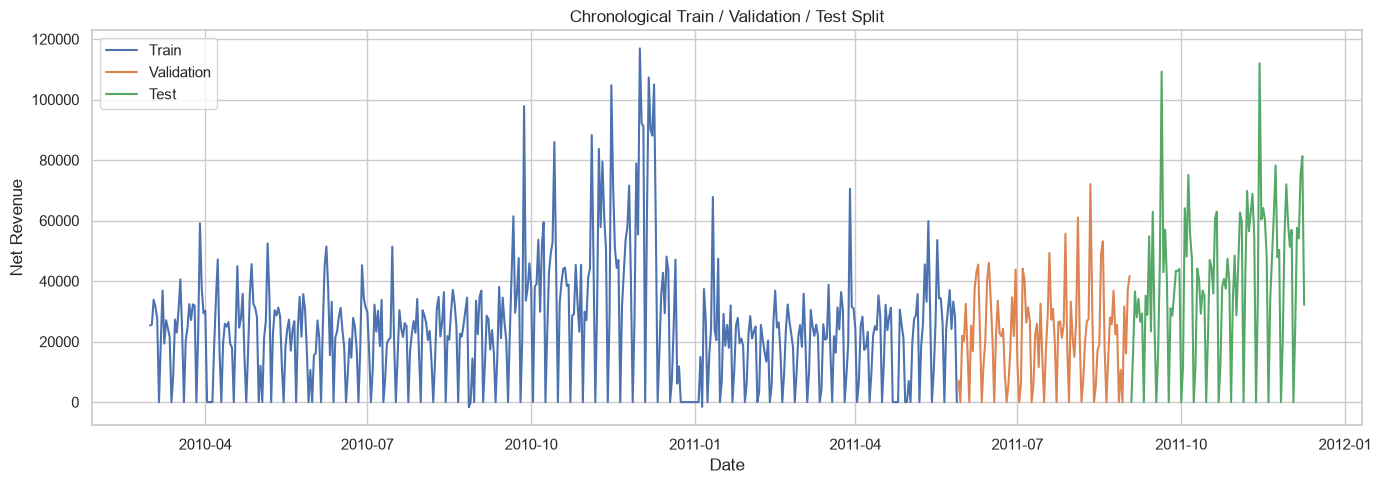

In [11]:
plt.figure(
    figsize=(14, 5)
)

plt.plot(
    train_df["date"],
    train_df[TARGET],
    label="Train",
)

plt.plot(
    validation_df["date"],
    validation_df[TARGET],
    label="Validation",
)

plt.plot(
    test_df["date"],
    test_df[TARGET],
    label="Test",
)

plt.title(
    "Chronological Train / Validation / Test Split"
)

plt.xlabel("Date")
plt.ylabel("Net Revenue")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Reuse the package metric; actuals equal to zero are excluded from MAPE.
from ml.models.evaluation import safe_mape

In [13]:
# Keep the notebook's existing function name so downstream cells stay unchanged.
from ml.models.evaluation import evaluate_regression as evaluate_model

In [14]:
results = []
# Baseline 1 – Naive Forecast
NAIVE_COLUMN = (
    f"{TARGET}_lag_1"
)

print(NAIVE_COLUMN)

net_revenue_lag_1


In [15]:
naive_validation_pred = (
    validation_df[NAIVE_COLUMN]
)

naive_validation_metrics = (
    evaluate_model(
        model_name="Naive lag-1",
        split_name="validation",
        y_true=validation_df[TARGET],
        y_pred=naive_validation_pred,
    )
)

results.append(
    naive_validation_metrics
)

naive_test_pred = (
    test_df[NAIVE_COLUMN]
)

naive_test_metrics = (
    evaluate_model(
        model_name="Naive lag-1",
        split_name="test",
        y_true=test_df[TARGET],
        y_pred=naive_test_pred,
    )
)

results.append(
    naive_test_metrics
)

pd.DataFrame(results)

,model,split,MAE,RMSE,MAPE_pct,R2
0,Naive lag-1,validation,15208.789155,18422.140877,65.457792,-0.425945
1,Naive lag-1,test,22677.058980,28886.711927,46.933541,-0.463364


In [16]:
# Baseline 2 – Moving Average
# Moving Average 7

MOVING_AVERAGE_COLUMN = (
    f"{TARGET}_rolling_mean_7"
)
# Validation

ma_validation_pred = (
    validation_df[
        MOVING_AVERAGE_COLUMN
    ]
)

results.append(
    evaluate_model(
        model_name="Moving average 7",
        split_name="validation",
        y_true=validation_df[TARGET],
        y_pred=ma_validation_pred,
    )
)

# Test
ma_test_pred = (
    test_df[
        MOVING_AVERAGE_COLUMN
    ]
)

results.append(
    evaluate_model(
        model_name="Moving average 7",
        split_name="test",
        y_true=test_df[TARGET],
        y_pred=ma_test_pred,
    )
)

pd.DataFrame(results)

,model,split,MAE,RMSE,MAPE_pct,R2
0,Naive lag-1,validation,15208.789155,18422.140877,65.457792,-0.425945
1,Naive lag-1,test,22677.058980,28886.711927,46.933541,-0.463364
2,Moving average 7,validation,12445.578150,15881.538341,52.130429,-0.059761
3,Moving average 7,test,17960.917589,23447.974269,36.138788,0.035801


In [17]:
# Moving Average Forecast
# Moving Average window
moving_average_validation_results = []

for window in (
    7,
    14,
    30,
):
    column = (
        f"{TARGET}"
        f"_rolling_mean_{window}"
    )

    metrics = evaluate_model(
        model_name=(
            f"Moving average {window}"
        ),
        split_name="validation",
        y_true=validation_df[TARGET],
        y_pred=validation_df[column],
    )

    moving_average_validation_results.append(
        metrics
    )

    # Compare
    moving_average_comparison = (
    pd.DataFrame(
        moving_average_validation_results
    )
    .sort_values("RMSE")
    .reset_index(drop=True)
)

moving_average_comparison

,model,split,MAE,RMSE,MAPE_pct,R2
0,Moving average 30,validation,12040.571812,15489.061601,49.500329,-0.008028
1,Moving average 14,validation,12464.815919,15870.713483,52.063305,-0.058316
2,Moving average 7,validation,12445.578150,15881.538341,52.130429,-0.059761


In [18]:
best_moving_average = (
    moving_average_comparison
    .iloc[0]
)

best_moving_average

model       Moving average 30
split              validation
MAE              12040.571812
RMSE             15489.061601
MAPE_pct            49.500329
R2                  -0.008028
Name: 0, dtype: object

In [19]:
# Baseline 3 – Linear Regression
# The imputer and scaler are fitted only on the training period through a scikit-learn Pipeline.
X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_validation = validation_df[FEATURES]
y_validation = validation_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print(
    "Train:",
    X_train.shape,
    y_train.shape,
)

print(
    "Validation:",
    X_validation.shape,
    y_validation.shape,
)

print(
    "Test:",
    X_test.shape,
    y_test.shape,
)

Train: (454, 43) (454,)
Validation: (97, 43) (97,)
Test: (98, 43) (98,)


In [1]:
# Reuse the shared imputer/scaler/Linear Regression pipeline; fit on train only.
linear_model = build_linear_regression_pipeline()
linear_model.fit(X_train, y_train)

NameError: name 'build_linear_regression_pipeline' is not defined

In [21]:
# Predict
linear_validation_pred = (
    linear_model.predict(
        X_validation
    )
)

linear_test_pred = (
    linear_model.predict(
        X_test
    )
)

# Valuation validation
results.append(
    evaluate_model(
        model_name="Linear Regression",
        split_name="validation",
        y_true=y_validation,
        y_pred=linear_validation_pred,
    )
)

results.append(
    evaluate_model(
        model_name="Linear Regression",
        split_name="test",
        y_true=y_test,
        y_pred=linear_test_pred,
    )
)

# Compare baseline models
results_df = (
    pd.DataFrame(results)
    .sort_values(
        [
            "split",
            "RMSE",
        ]
    )
    .reset_index(drop=True)
)

results_df.round(3)

,model,split,MAE,RMSE,MAPE_pct,R2
0,Linear Regression,test,17819.681,21247.470,47.061,0.208
1,Moving average 7,test,17960.918,23447.974,36.139,0.036
2,Naive lag-1,test,22677.059,28886.712,46.934,-0.463
3,Linear Regression,validation,9528.868,12752.753,38.241,0.317
4,Moving average 7,validation,12445.578,15881.538,52.130,-0.060
5,Naive lag-1,validation,15208.789,18422.141,65.458,-0.426


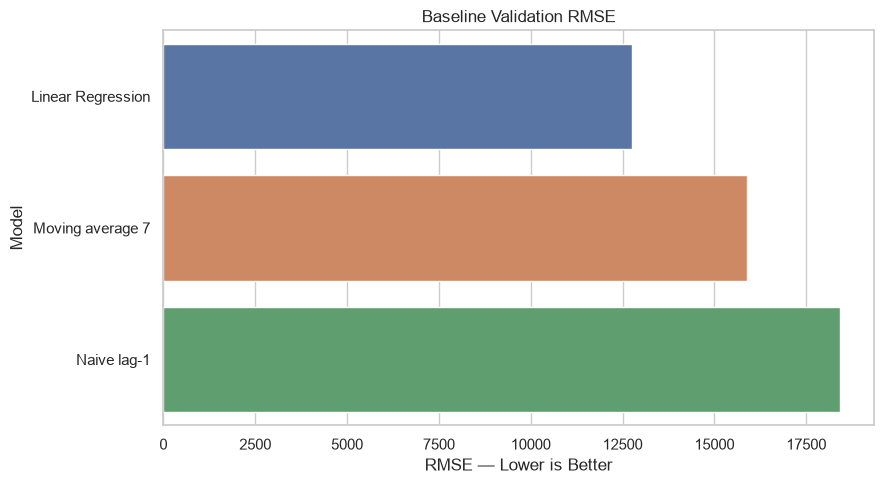

In [22]:
# RMSE
validation_results = (
    results_df
    .query(
        "split == 'validation'"
    )
    .sort_values("RMSE")
)

plt.figure(
    figsize=(9, 5)
)

sns.barplot(
    data=validation_results,
    x="RMSE",
    y="model",
    hue="model",
    legend=False,
)

plt.title(
    "Baseline Validation RMSE"
)

plt.xlabel(
    "RMSE — Lower is Better"
)

plt.ylabel("Model")
plt.tight_layout()
plt.show()

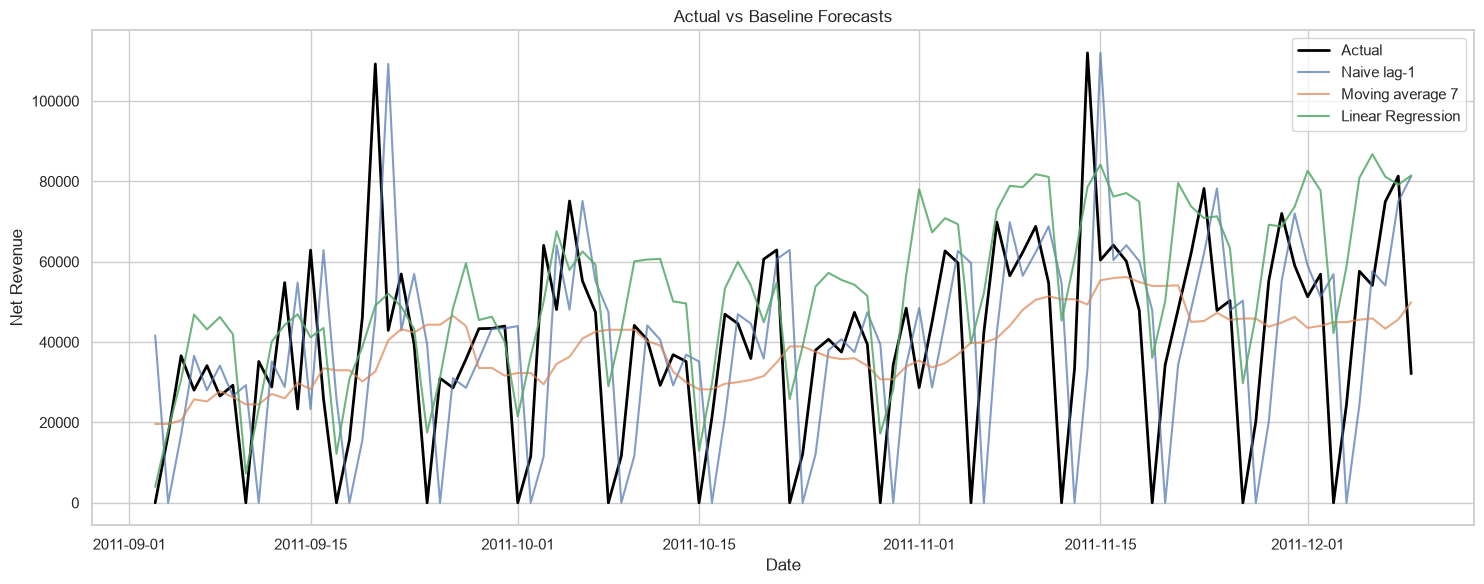

In [23]:
# Plot test predictions
# Actual and Prediction comparison
predictions_df = (
    test_df[
        [
            "date",
            TARGET,
        ]
    ]
    .copy()
)

predictions_df["naive_lag_1"] = (
    naive_test_pred.to_numpy()
)

predictions_df["moving_average_7"] = (
    ma_test_pred.to_numpy()
)

predictions_df["linear_regression"] = (
    linear_test_pred
)

plt.figure(
    figsize=(15, 6)
)

plt.plot(
    predictions_df["date"],
    predictions_df[TARGET],
    label="Actual",
    color="black",
    linewidth=2,
)

plt.plot(
    predictions_df["date"],
    predictions_df["naive_lag_1"],
    label="Naive lag-1",
    alpha=0.7,
)

plt.plot(
    predictions_df["date"],
    predictions_df[
        "moving_average_7"
    ],
    label="Moving average 7",
    alpha=0.7,
)

plt.plot(
    predictions_df["date"],
    predictions_df[
        "linear_regression"
    ],
    label="Linear Regression",
    alpha=0.85,
)

plt.title(
    "Actual vs Baseline Forecasts"
)

plt.xlabel("Date")
plt.ylabel("Net Revenue")
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
# Check Linear Regression
linear_estimator = (
    linear_model
    .named_steps["model"]
)
# Inspect Linear Regression coefficients
coefficients = pd.DataFrame(
    {
        "feature": FEATURES,
        "coefficient": (
            linear_estimator.coef_
        ),
    }
)

coefficients[
    "absolute_coefficient"
] = (
    coefficients["coefficient"]
    .abs()
)

top_coefficients = (
    coefficients
    .sort_values(
        "absolute_coefficient",
        ascending=False,
    )
    .head(20)
)

top_coefficients

,feature,coefficient,absolute_coefficient
4,month,68999.576423,68999.576423
2,day_of_year,-58889.213532,58889.213532
6,year,15575.231561,15575.231561
40,net_revenue_expanding_std,-13660.801298,13660.801298
27,net_revenue_rolling_mean_7,13549.763916,13549.763916
7,is_weekend,-11653.654239,11653.654239
14,month_sin,10116.426638,10116.426638
0,day_of_week,8975.009100,8975.009100
15,month_cos,8339.003896,8339.003896
31,net_revenue_rolling_mean_14,-6905.424361,6905.424361


In [25]:
# Check negative prediction
negative_predictions = (
    linear_test_pred < 0
).sum()

print(
    "Negative predictions:",
    negative_predictions,
)

Negative predictions: 0


In [26]:
linear_test_pred_clipped = np.maximum(
    linear_test_pred,
    0,
)

evaluate_model(
    model_name="Linear Regression clipped",
    split_name="test",
    y_true=y_test,
    y_pred=linear_test_pred_clipped,
)

{'model': 'Linear Regression clipped',
 'split': 'test',
 'MAE': 17819.680883065277,
 'RMSE': np.float64(21247.470421333805),
 'MAPE_pct': np.float64(47.06067376563597),
 'R2': 0.20828186166690466}

In [27]:
# Save Linear Regression pipeline
LINEAR_MODEL_PATH = (
    MODEL_DIR
    / "linear_regression_baseline.joblib"
)
# Save baseline artifacts
joblib.dump(
    linear_model,
    LINEAR_MODEL_PATH,
)

# Save metric
METRICS_PATH = (
    RESULT_DIR
    / "baseline_model_metrics.csv"
)

results_df.to_csv(
    METRICS_PATH,
    index=False,
)

# save predictions
PREDICTIONS_PATH = (
    RESULT_DIR
    / "baseline_test_predictions.csv"
)

predictions_df.to_csv(
    PREDICTIONS_PATH,
    index=False,
)

# save info split
SPLIT_PATH = (
    RESULT_DIR
    / "time_split_summary.csv"
)

split_summary.to_csv(
    SPLIT_PATH,
    index=False,
)

# save metadata
baseline_metadata = {
    "target": TARGET,
    "features": FEATURES,
    "split_strategy": (
        "chronological_70_15_15"
    ),
    "train_start": str(
        train_df["date"]
        .min()
        .date()
    ),
    "train_end": str(
        train_df["date"]
        .max()
        .date()
    ),
    "validation_start": str(
        validation_df["date"]
        .min()
        .date()
    ),
    "validation_end": str(
        validation_df["date"]
        .max()
        .date()
    ),
    "test_start": str(
        test_df["date"]
        .min()
        .date()
    ),
    "test_end": str(
        test_df["date"]
        .max()
        .date()
    ),
}

In [28]:
BASELINE_METADATA_PATH = (
    RESULT_DIR
    / "baseline_metadata.json"
)

BASELINE_METADATA_PATH.write_text(
    json.dumps(
        baseline_metadata,
        indent=2,
    ),
    encoding="utf-8",
)

1391

In [29]:
assert len(train_df) > 0
assert len(validation_df) > 0
assert len(test_df) > 0

assert (
    train_df["date"].max()
    < validation_df["date"].min()
)

assert (
    validation_df["date"].max()
    < test_df["date"].min()
)

assert len(predictions_df) == len(test_df)
assert not predictions_df.isna().any().any()